# Experiment 2: The eight queens problem
**Aim.** To formulate the eight queens problem as a constraint satisfaction problem, to solve it by generate-and-test
and by backtracking, and to measure the effect of representation and search strategy on cost.

**Objectives:** state the CSP; show how encoding removes conflict classes; implement generate-and-test and
backtracking; count nodes; compare over $n = 4 \dots 10$.

## Theory (summary)
* Naive: queens over 64 squares, $\binom{64}{8} = 4\,426\,165\,368$ placements.
* One queen per column (variable = column, value = row): $8^8 = 16\,777\,216$.
* Permutation (rows distinct too): $8! = 40\,320$.
* Diagonals must always be tested: $|r_i - r_j| = |i - j|$.

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figs', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

In [2]:
from math import comb, factorial
print('C(64,8) =', comb(64, 8), '  8^8 =', 8**8, '  8! =', factorial(8))

C(64,8) = 4426165368   8^8 = 16777216   8! = 40320


## Example 1: Generate and test

In [3]:
from itertools import permutations
import time

def conflicts(board):
    '''board[c] = row of the queen in column c. Count attacking pairs.'''
    n = len(board); bad = 0
    for i in range(n):
        for j in range(i+1, n):
            if board[i] == board[j] or abs(board[i]-board[j]) == abs(i-j):
                bad += 1
    return bad

t0 = time.perf_counter()
sols = [p for p in permutations(range(8)) if conflicts(p) == 0]
print(len(sols), 'solutions in', round(time.perf_counter()-t0, 4), 's')
print('first:', sols[0])

92 solutions in 0.2037 s
first: (0, 4, 7, 5, 2, 6, 1, 3)


## Example 2: Backtracking with pruning

In [4]:
def is_safe(board, col, row):
    '''Can a queen sit at (row, col), given columns 0..col-1 are placed?'''
    for c in range(col):
        if board[c] == row or abs(board[c]-row) == abs(c-col):
            return False
    return True

def solve(n=8):
    sols, nodes = [], [0]
    def place(board, col):
        if col == n:
            sols.append(tuple(board)); return
        for row in range(n):
            nodes[0] += 1
            if is_safe(board, col, row):
                board[col] = row          # place
                place(board, col+1)
                board[col] = -1           # UNDO: the 'back' in backtracking
    place([-1]*n, 0)
    return sols, nodes[0]

bt_sols, nodes = solve(8)
print(len(bt_sols), 'solutions,', nodes, 'nodes visited')
print('same solution set as generate-and-test:', set(bt_sols) == set(sols))

92 solutions, 15720 nodes visited
same solution set as generate-and-test: True


In [5]:
def print_board(b):
    n = len(b)
    for r in range(n):
        print(' '.join('Q' if b[c] == r else '.' for c in range(n)))

print('First solution for n = 8:', bt_sols[0])
print_board(bt_sols[0])

First solution for n = 8: (0, 4, 7, 5, 2, 6, 1, 3)
Q . . . . . . .
. . . . . . Q .
. . . . Q . . .
. . . . . . . Q
. Q . . . . . .
. . . Q . . . .
. . . . . Q . .
. . Q . . . . .


## Example 3: Scaling, and where each method fails

In [6]:
rows = []
print(f"{'n':>3} {'solutions':>10} {'nodes':>10} {'backtrack':>11} {'generate':>11}")
for n in range(4, 11):
    t0 = time.perf_counter(); s, nd = solve(n); tb = time.perf_counter()-t0
    t0 = time.perf_counter()
    g = [p for p in permutations(range(n)) if conflicts(p) == 0]
    tg = time.perf_counter()-t0
    assert len(g) == len(s), 'methods disagree!'
    rows.append((n, len(s), nd, tb, tg))
    print(f'{n:>3} {len(s):>10} {nd:>10} {tb:>10.4f}s {tg:>10.4f}s')

  n  solutions      nodes   backtrack    generate
  4          2         60     0.0000s     0.0000s
  5         10        220     0.0001s     0.0002s
  6          4        894     0.0004s     0.0024s
  7         40       3584     0.0018s     0.0190s


  8         92      15720     0.0080s     0.1808s


  9        352      72378     0.0442s     2.0715s


 10        724     348150     0.2232s    34.9817s


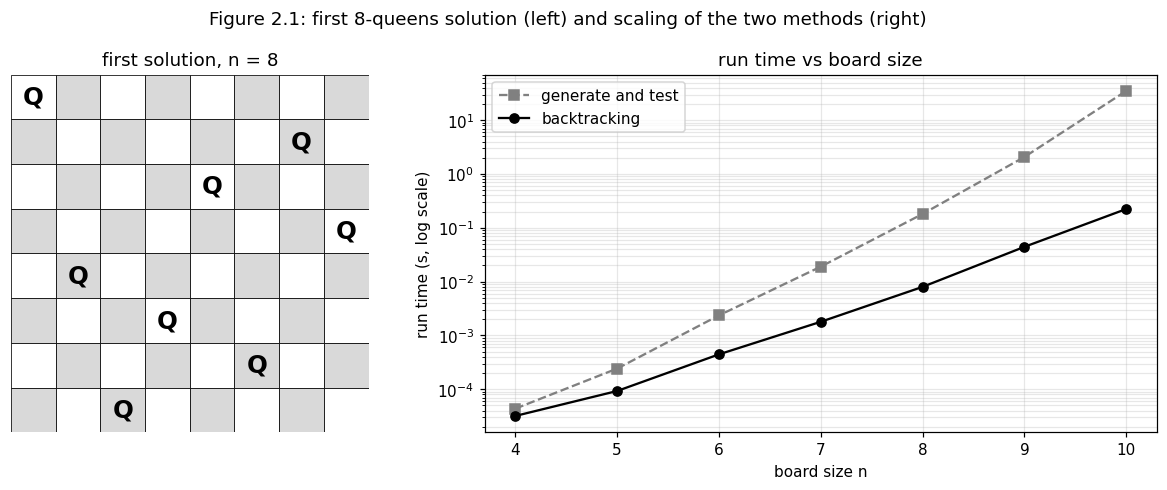

speed-up at n=10: 157x


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
b = bt_sols[0]; n = len(b)
for r in range(n):
    for c in range(n):
        ax1.add_patch(plt.Rectangle((c, n-1-r), 1, 1, color='0.85' if (r+c) % 2 else 'white', ec='k', lw=0.5))
for c, r in enumerate(b):
    ax1.text(c+0.5, n-1-r+0.5, 'Q', ha='center', va='center', fontsize=16, weight='bold')
ax1.set_xlim(0, n); ax1.set_ylim(0, n); ax1.set_aspect('equal'); ax1.axis('off')
ax1.set_title('first solution, n = 8')

ns = [r[0] for r in rows]
ax2.semilogy(ns, [max(r[4], 1e-6) for r in rows], 's--', color='0.5', label='generate and test')
ax2.semilogy(ns, [max(r[3], 1e-6) for r in rows], 'o-', color='k', label='backtracking')
ax2.set_xlabel('board size n'); ax2.set_ylabel('run time (s, log scale)')
ax2.legend(); ax2.grid(alpha=0.3, which='both'); ax2.set_title('run time vs board size')
fig.suptitle('Figure 2.1: first 8-queens solution (left) and scaling of the two methods (right)')
plt.tight_layout(); plt.savefig('figs/fig2_1_queens.png'); plt.show()
print(f'speed-up at n=10: {rows[-1][4]/rows[-1][3]:.0f}x')

### Symmetry check: 92 solutions reduce to 12 fundamental ones

In [8]:
def transforms(b):
    n = len(b)
    pts = [(c, r) for c, r in enumerate(b)]
    out = []
    for k in range(4):
        for flip in (False, True):
            q = pts
            for _ in range(k):
                q = [(r, n-1-c) for c, r in q]          # rotate 90 degrees
            if flip:
                q = [(n-1-c, r) for c, r in q]          # mirror
            nb_ = [0]*n
            for c, r in q: nb_[c] = r
            out.append(tuple(nb_))
    return out

classes = {min(transforms(s)) for s in bt_sols}
print('fundamental solutions:', len(classes))
print('images per class:', sorted(len(set(transforms(c))) for c in classes))

fundamental solutions: 12
images per class: [4, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]


## Observations to record
The table above lists, for each $n$, the number of solutions, the nodes visited and the run time of both methods.
The first solution for $n = 8$ is printed as a board.

## Discussion
* **Expected:** both methods find 92 solutions for $n = 8$, and backtracking is far cheaper because it prunes partial boards.
* **Observed:** solution counts agree for every $n$ (asserted in code). Backtracking visits 15 720 nodes at $n = 8$.
  The gap in run time grows with $n$.
* **Symmetry:** 11 classes have 8 images and 1 class has only 4, because that solution is symmetric under a 180° rotation.
  This gives $11\times8 + 4 = 92$, not $12\times8 = 96$.

## Viva questions (short answers)
1. A list of row indices makes column conflicts impossible. Using a permutation also removes row conflicts. Diagonal conflicts are never removed by construction.
2. **Too many solutions?** Too many solutions means some attacks are not being detected. Check the test in `is_safe`, for example a wrong comparison or a missing `abs` in the diagonal condition. (Work out the exact character for the viva by trying it.)
3. Columns to the right are still empty, so they cannot attack.
4. Pruning cuts off whole subtrees early, so the effective search is tiny compared with $n!$.
5. See the symmetry check above (8 symmetries of the square; one solution is 180°-symmetric).